In [1]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from torch import nn

In [2]:
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

X, y = make_blobs(n_samples=1000,
                            n_features=NUM_FEATURES,
                            centers=NUM_CLASSES,
                            cluster_std=1.5,
                            random_state=RANDOM_SEED)

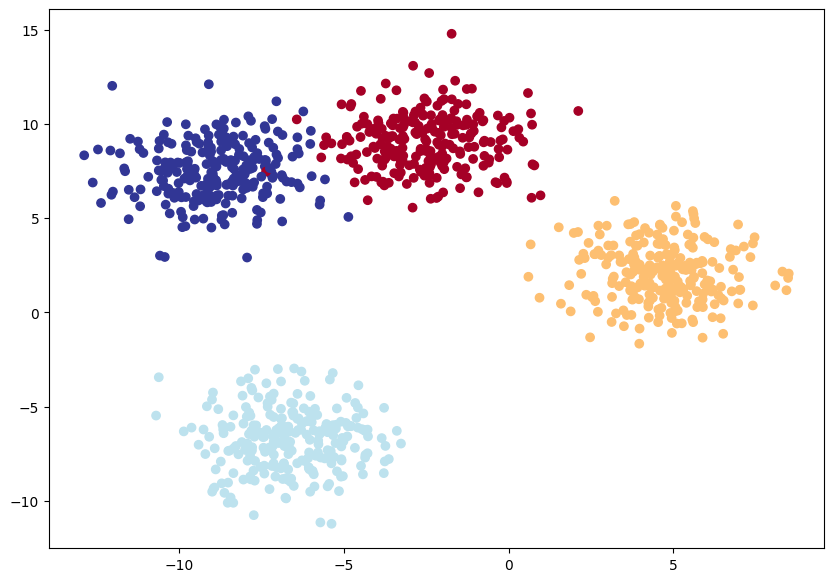

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y,
                                                    test_size=0.2,
                                                    random_state=RANDOM_SEED)

plt.figure(figsize=(10,7))
plt.scatter(X[:,0],X[:,1], c=y, cmap=plt.cm.RdYlBu);

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [5]:
X = torch.tensor(X, dtype=torch.float, device=device)
y = torch.tensor(y, dtype=torch.long, device=device)

In [6]:
class BlobModel_V1(nn.Module):
    def __init__(self, hidden_out, hidden_layers):
        super().__init__()
        layers = [nn.Linear(in_features=2, out_features=hidden_out), nn.ReLU()]
        
        for _ in range (hidden_layers):
            layers.append(nn.Linear(in_features=hidden_out, out_features=hidden_out))
            layers.append(nn.ReLU())
        
        layers.append(nn.Linear(in_features=hidden_out, out_features=4))
        self.layer_stack = nn.Sequential(*layers)

    def forward(self, x):
        return self.layer_stack(x)

In [7]:
bogus_model = BlobModel_V1(hidden_out=10,hidden_layers=6).to(device)
bogus_model

BlobModel_V1(
  (layer_stack): Sequential(
    (0): Linear(in_features=2, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=10, bias=True)
    (5): ReLU()
    (6): Linear(in_features=10, out_features=10, bias=True)
    (7): ReLU()
    (8): Linear(in_features=10, out_features=10, bias=True)
    (9): ReLU()
    (10): Linear(in_features=10, out_features=10, bias=True)
    (11): ReLU()
    (12): Linear(in_features=10, out_features=10, bias=True)
    (13): ReLU()
    (14): Linear(in_features=10, out_features=4, bias=True)
  )
)

In [8]:
X_train, y_train = torch.tensor(X_train, dtype=torch.float, device=device), torch.tensor(y_train, device=device)
X_test, y_test = torch.tensor(X_test, dtype=torch.float, device=device), torch.tensor(y_test, device=device)

In [9]:
bogus_model.eval()
with torch.inference_mode():
    train_logits = bogus_model(X_train)
train_logits

tensor([[ 0.4047,  0.0785, -0.2590,  0.0548],
        [ 0.4042,  0.0774, -0.2591,  0.0559],
        [ 0.4114,  0.0817, -0.2616,  0.0477],
        ...,
        [ 0.4041,  0.0776, -0.2590,  0.0558],
        [ 0.4087,  0.0778, -0.2621,  0.0510],
        [ 0.4047,  0.0772, -0.2598,  0.0549]], device='cuda:0')

In [10]:
pred = torch.softmax(train_logits, dim=1).argmax(dim=1)
pred[:10]

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], device='cuda:0')

In [11]:
pred.unique()

tensor([0], device='cuda:0')

In [12]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params = bogus_model.parameters(),
                            lr=0.04)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=200,
)

In [13]:
from helper_functions import accuracy_fn

In [14]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 2500

train_loss_list = []
test_loss_list = []
iterations = []

for epoch in range(epochs):
    ### Training

    
    bogus_model.train()

    train_logits = bogus_model(X_train)
    train_pred = torch.softmax(train_logits, dim=1).argmax(dim=1)
    train_acc = accuracy_fn(y_train, 
                            train_pred)
    
    train_loss = loss_fn(train_logits, y_train.long())
    
    optimizer.zero_grad()
    train_loss.backward()
    optimizer.step()

    bogus_model.eval()
    with torch.inference_mode():
        test_logits = bogus_model(X_test)
        test_preds = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_acc = accuracy_fn(y_test,
                                test_preds)
        
        test_loss = loss_fn(test_logits, y_test.long())
        
    if epoch % 50 == 0:
        iterations.append(epoch)
        train_loss_list.append(train_loss)
        test_loss_list.append(test_loss)

        print(f"Epoch: {epoch} | Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}% | Test Loss: {test_loss: .4f}, Test Accuracy: {test_acc:.4f}%")
    
        scheduler.step(test_loss)

Epoch: 0 | Loss: 1.4126, Train Accuracy: 25.1250% | Test Loss:  1.4212, Test Accuracy: 24.5000%
Epoch: 50 | Loss: 1.3932, Train Accuracy: 25.1250% | Test Loss:  1.3998, Test Accuracy: 24.5000%
Epoch: 100 | Loss: 1.3878, Train Accuracy: 25.1250% | Test Loss:  1.3934, Test Accuracy: 24.5000%
Epoch: 150 | Loss: 1.3858, Train Accuracy: 25.1250% | Test Loss:  1.3910, Test Accuracy: 24.5000%
Epoch: 200 | Loss: 1.3847, Train Accuracy: 26.1250% | Test Loss:  1.3897, Test Accuracy: 20.5000%
Epoch: 250 | Loss: 1.3836, Train Accuracy: 26.1250% | Test Loss:  1.3885, Test Accuracy: 20.5000%
Epoch: 300 | Loss: 1.3823, Train Accuracy: 26.1250% | Test Loss:  1.3871, Test Accuracy: 20.5000%
Epoch: 350 | Loss: 1.3809, Train Accuracy: 26.1250% | Test Loss:  1.3857, Test Accuracy: 20.5000%
Epoch: 400 | Loss: 1.3789, Train Accuracy: 26.1250% | Test Loss:  1.3839, Test Accuracy: 20.5000%
Epoch: 450 | Loss: 1.3759, Train Accuracy: 26.1250% | Test Loss:  1.3812, Test Accuracy: 20.5000%
Epoch: 500 | Loss: 1.37

C:\Users\emman\AppData\Local\Temp\ipykernel_4672\1252086725.py:2: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  plt.plot(iterations, torch.tensor(train_loss_list).detach().cpu().numpy(), c="r", label="Train Loss")


<function matplotlib.pyplot.show(close=None, block=None)>

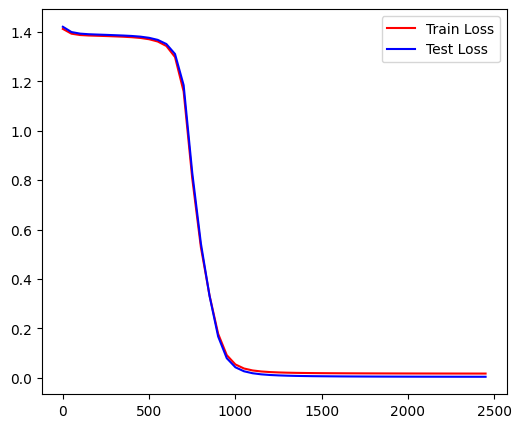

In [15]:
plt.figure(figsize=(6,5))
plt.plot(iterations, torch.tensor(train_loss_list).detach().cpu().numpy(), c="r", label="Train Loss")
plt.plot(iterations, torch.tensor(test_loss_list).detach().cpu().numpy(), c="b", label = "Test Loss")
plt.legend()
plt.show

In [16]:
from helper_functions import plot_decision_boundary

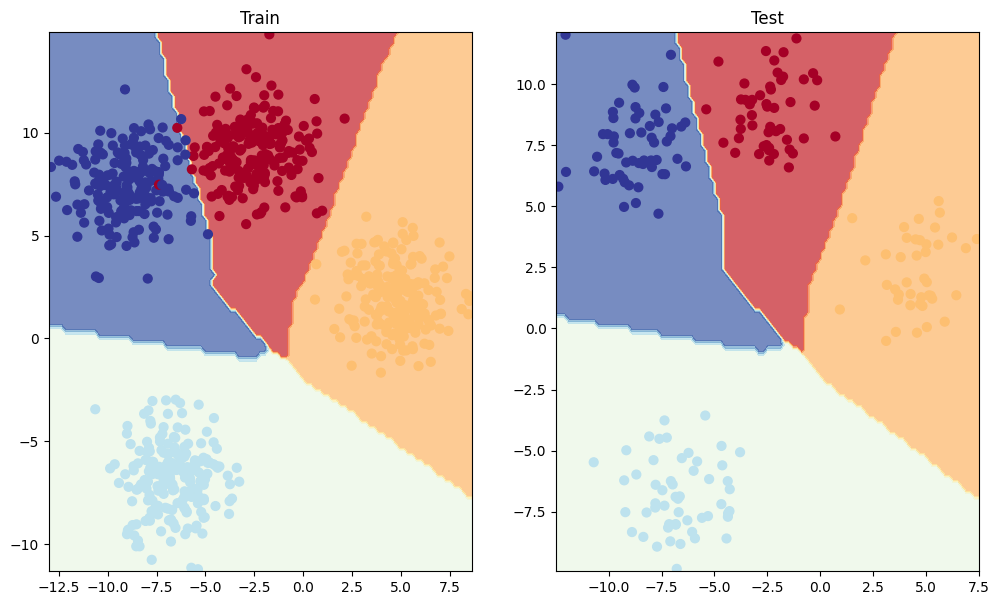

In [17]:
plt.figure(figsize=(12,7))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(bogus_model, X_train, y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(bogus_model, X_test, y_test)
